In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import os
import torch
import torch.nn.functional as F
from training import load_checkpoint
from utils import get_device, canonicalize
from config_plt import config_plt, get_fig_ax, save_my_fig, colors
config_plt()

In [2]:
df3 = pd.read_csv("./fitting-results/train_emulator_3.csv")
df5 = pd.read_csv("./fitting-results/train_emulator_5.csv")
df10 = pd.read_csv("./fitting-results/train_emulator_10.csv")
df345 = pd.read_csv("./fitting-results/train_emulator_3_4_5.csv")

df3_eval = df3[~df3["eval_ce_loss_train"].isna()]
df5_eval = df5[~df5["eval_ce_loss_train"].isna()]
df10_eval = df10[~df10["eval_ce_loss_train"].isna()]
df345_eval = df345[~df345["eval_ce_loss_train"].isna()]

dfs = [df3, df5, df10, df345]
dfs_eval = [df3_eval, df5_eval, df10_eval, df345_eval]
ks = ["3", "5", "10", "3_4_5"]

df_df_eval_k_zip = zip(dfs, dfs_eval, ks)

./figures/loss_3


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


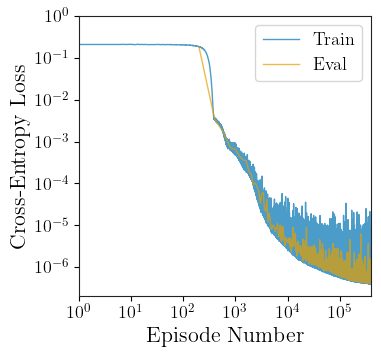

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


./figures/loss_5


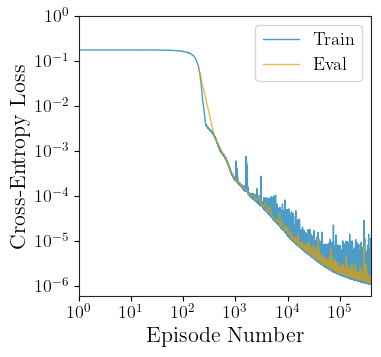

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


./figures/loss_10


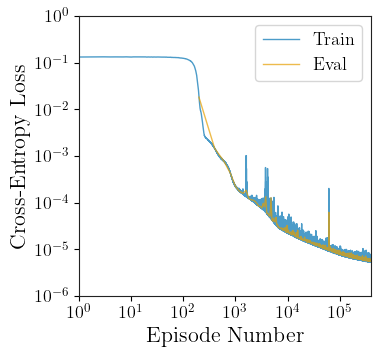

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


./figures/loss_3_4_5


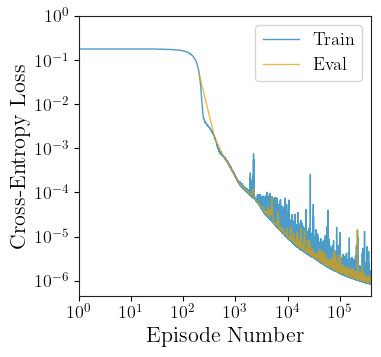

In [3]:
def plot_loss(df, df_eval, k, 
              figsize=(4, 3.5),
              # Margin parameters (as fraction of figure size)
              left=0.23,    # Space for y-axis label and tick labels
              right=0.96,   # Space on right side
              bottom=0.17,  # Space for x-axis label and tick labels
              top=0.97):    # Space on top
    
    int_formatter = ticker.StrMethodFormatter('{x:,.0f}')
    alpha = 0.7
    fig, ax = get_fig_ax(figsize)
    
    # Adjust the subplot margins
    fig.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
    
    ax.plot(df.index, df["train_ce_loss"], linewidth=1, color=colors[0], alpha=alpha, label="Train")
    ax.plot(df_eval.index, df_eval["eval_ce_loss_train"], linewidth=1, color=colors[1], alpha=alpha, label="Eval")
    ax.set_yscale("log")
    yticks = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1e0]
    ax.set_yticks(yticks)
    ax.minorticks_off()
    ax.set_ylabel("Cross-Entropy Loss")

    ax.set_xscale("log")
    xticks = [1e0, 1e1, 1e2, 1e3, 1e4, 1e5]
    ax.set_xticks(xticks)
    ax.set_xlim(1, df.shape[0]+1)
    ax.set_xlabel("Episode Number")
    
    legend = ax.legend()
    for line in legend.get_lines():
        line.set_linewidth(1)
    
    save_my_fig(fig, f"loss_{k}")
    plt.show()

# Usage with custom margins if needed:
for df, df_eval, k in df_df_eval_k_zip:
    plot_loss(df, df_eval, k)
    # Or with custom adjustments:
    # plot_loss(df, df_eval, k, left=0.20, bottom=0.18)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


./figures/errors_3_4_5


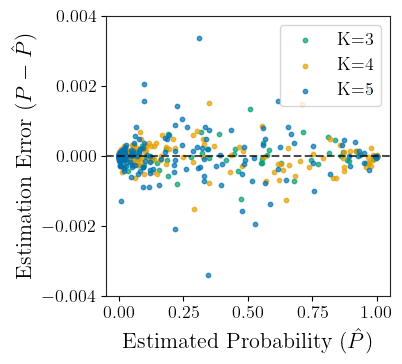

In [4]:
def plot_errors(checkpoint_path, 
              figsize=(4, 3.5),
              seed=42,
              # Margin parameters (as fraction of figure size)
              left=0.25,    # Space for y-axis label and tick labels
              right=0.96,   # Space on right side
              bottom=0.17,  # Space for x-axis label and tick labels
              top=0.97,     # Space on top
              eval_batch_size=400,
              data_checkpoint_dir="simulation-data-checkpoints"):

    # Set seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    int_formatter = ticker.StrMethodFormatter('{x:,.0f}')
    alpha = 0.7
    fig, ax = get_fig_ax(figsize)
    fig.subplots_adjust(left=left, right=right, bottom=bottom, top=top)

    model, epoch, loss = load_checkpoint(checkpoint_path)    
    # Get k from the checkpoint path (e.g., "3_4_5.pt" -> [3, 4, 5])
    checkpoint_name = os.path.basename(checkpoint_path)
    checkpoint_no_prefix = checkpoint_name.replace('checkpoint_emulator_', '')
    k_str = checkpoint_no_prefix.replace('.pt', '')
    k_values = [int(x) for x in k_str.split('_')]
    
    model.eval()
    device = get_device()
    
    # Colors for different K values
    k_colors = {
        3: 2,
        4: 1,
        5: 0
    }
    
    with torch.no_grad():
        for k in k_values:
            # Load saved evaluation data
            eval_buffer_path = os.path.join(data_checkpoint_dir, f"{k}-eval_cholesky.pt")
            eval_data = torch.load(eval_buffer_path, map_location=device, weights_only=True)
            
            v = eval_data['v'].to(device)
            dtype = v.dtype
            buffer_size = v.shape[0]
            L = eval_data['L'].to(device)
            y = eval_data['y'].to(device)
            Omega = L @ L.transpose(-1, -2)
            Sigma = torch.zeros(buffer_size, k, k, device=device, dtype=v.dtype)
            Sigma[:, 0, 0] = 1.0
            Sigma[:, 1:, 1:] = Omega
            v_star, cov_star, c_star = canonicalize(v, Sigma)
            
            # Sample a subset if needed
            if eval_batch_size < buffer_size:
                indices = torch.randperm(buffer_size)[:eval_batch_size]
                v_star = v_star[indices]
                cov_star = cov_star[indices]
                y = y[indices]
            
            # Get model predictions
            logits = model(v_star, cov_star)
            yhat = F.softmax(logits, dim=-1)
            
            # Plot
            ax.scatter(yhat.cpu().numpy().flatten(), 
                      y.cpu().numpy().flatten() - yhat.cpu().numpy().flatten(),
                      color=colors[k_colors[k]], label=f"K={k}", alpha=alpha, s=10)
    
    ax.axhline(0, color="black", linestyle="--", alpha=alpha)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.004, 0.004)
    ax.set_xlabel(r"Estimated Probability ($\hat{P}$)")
    ax.set_ylabel(r"Estimation Error ($P - \hat{P}$)")
    ax.legend(loc="upper right")
    
    save_my_fig(fig, f"errors_{k_str}")
    plt.show()

plot_errors("model-checkpoints/checkpoint_emulator_3_4_5.pt")